In [153]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [154]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [155]:
df = pd.read_excel("/content/drive/MyDrive/SEM 7/Coffee Shop Sales.xlsx")
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [156]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi data:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (149116, 11)

Nama kolom:
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

Lima baris pertama:


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(5)
memory usage: 12.5+ MB

Jumlah missing value:
transaction_id      0
transaction_date    0
transact

Filter data

In [157]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Penjualan per hari

In [158]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

print("\nStatistik deskriptif:")
display(data_harian["y"].describe())

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273



Statistik deskriptif:


,y
count,181.000000
mean,396.337017
std,129.535462
min,195.000000
25%,290.000000
50%,363.000000
75%,483.000000
max,769.000000


EDA

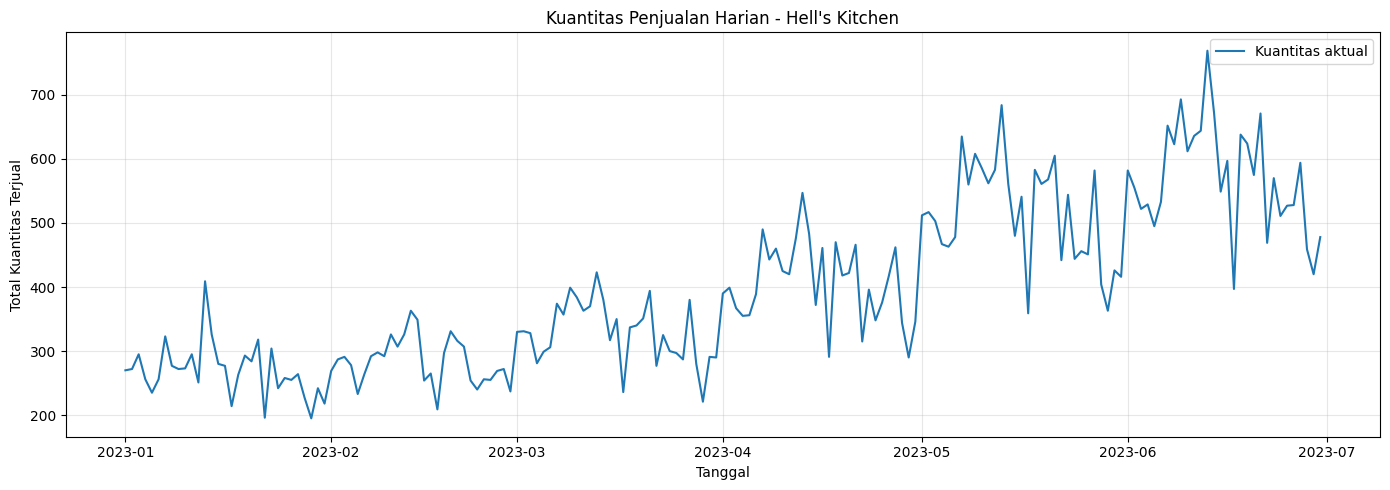

In [159]:
plt.figure(figsize=(14, 5))

plt.plot(
    data_harian["ds"],
    data_harian["y"],
    label="Kuantitas aktual"
)

plt.title("Kuantitas Penjualan Harian - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Total Kuantitas Terjual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pola penjualan berdasarkan hari

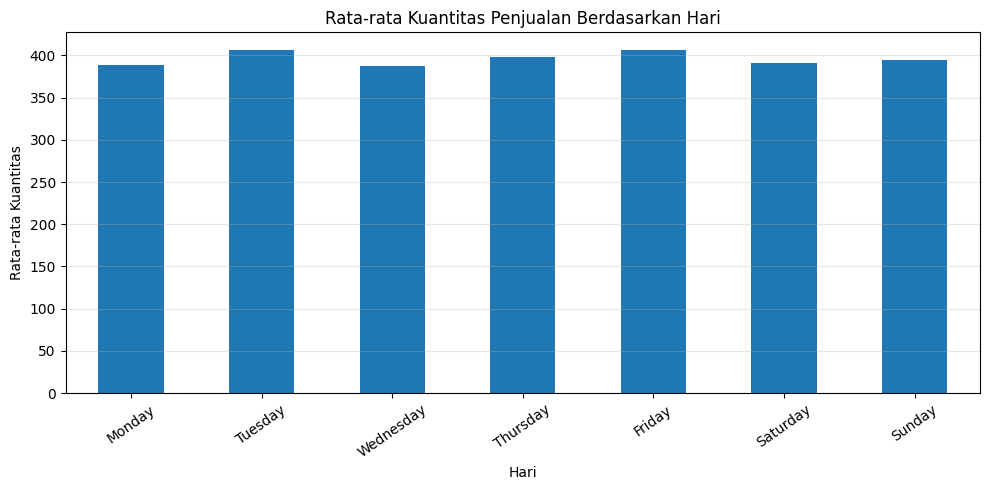

In [160]:
data_harian["nama_hari"] = (
    data_harian["ds"].dt.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

rata_hari = (
    data_harian
    .groupby("nama_hari")["y"]
    .mean()
    .reindex(urutan_hari)
)

plt.figure(figsize=(10, 5))
rata_hari.plot(kind="bar")

plt.title("Rata-rata Kuantitas Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Kuantitas")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Pemisahan data training dan testing

In [161]:
# Pastikan urutan tanggal sudah benar
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Pembagian berdasarkan waktu
split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][["ds", "y"]].copy()
test = data_harian.iloc[split_index:][["ds", "y"]].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train["ds"].min(), "sampai", train["ds"].max())

print("\nPeriode testing:")
print(test["ds"].min(), "sampai", test["ds"].max())

Jumlah data training: 144
Jumlah data testing: 37

Periode training:
2023-01-01 00:00:00 sampai 2023-05-24 00:00:00

Periode testing:
2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Fungsi evaluasi

In [162]:
import pandas as pd
import numpy as np
from prophet import Prophet

def evaluasi_model(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.maximum(
        np.asarray(prediksi, dtype=float), 0
    )

    error = aktual - prediksi

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE tidak terdefinisi jika nilai aktual = 0
    mask = aktual != 0
    mape = (
        np.mean(np.abs(error[mask] / aktual[mask])) * 100
        if mask.any() else np.nan
    )

    penyebut = np.abs(aktual) + np.abs(prediksi)
    smape_per_baris = np.divide(
        2 * np.abs(error),
        penyebut,
        out=np.zeros_like(penyebut, dtype=float),
        where=penyebut != 0
    )
    smape = np.mean(smape_per_baris) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "SMAPE (%)": smape
    }

Latih prophet baseline dan prophet jittering

In [163]:
# Salin dan rapikan data
train_asli = train[["ds", "y"]].copy()
validasi = test[["ds", "y"]].copy()

train_asli["ds"] = pd.to_datetime(train_asli["ds"])
validasi["ds"] = pd.to_datetime(validasi["ds"])

train_asli = train_asli.sort_values("ds").reset_index(drop=True)
validasi = validasi.sort_values("ds").reset_index(drop=True)

# MODEL A: Prophet dengan data training asli
model_baseline = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_baseline.fit(train_asli)

pred_baseline = model_baseline.predict(
    validasi[["ds"]]
)["yhat"].to_numpy()

# MODEL B: Prophet dengan noise injection pada training
rng = np.random.default_rng(42)

# Besar noise: 2% dari simpangan baku target training
besar_noise = 0.02 * train_asli["y"].std()

train_jitter = train_asli.copy()
noise = rng.normal(
    loc=0,
    scale=besar_noise,
    size=len(train_jitter)
)

# Penjualan tidak boleh negatif
train_jitter["y"] = np.maximum(
    train_jitter["y"].to_numpy() + noise,
    0
)

model_jitter = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_jitter.fit(train_jitter)

pred_jitter = model_jitter.predict(
    validasi[["ds"]]
)["yhat"].to_numpy()

# Evaluasi kedua model pada data validasi yang sama
hasil_perbandingan = pd.DataFrame([
    {
        "Model": "Prophet Baseline",
        **evaluasi_model(validasi["y"], pred_baseline)
    },
    {
        "Model": "Prophet + Jittering",
        **evaluasi_model(validasi["y"], pred_jitter)
    }
])

display(hasil_perbandingan.round(4))

,Model,MAE,RMSE,MAPE (%),SMAPE (%)
0,Prophet Baseline,87.2320,104.5342,17.6828,15.9248
1,Prophet + Jittering,87.8597,105.4581,17.8453,16.0231


Hasil prophet baseline & prophet jittering

In [164]:
metrik = ["MAE", "RMSE", "MAPE (%)", "SMAPE (%)"]

hasil = hasil_perbandingan.set_index("Model")

print("Perbandingan perubahan nilai error:")
for kolom in metrik:
    baseline = hasil.loc["Prophet Baseline", kolom]
    jitter = hasil.loc["Prophet + Jittering", kolom]

    perubahan = jitter - baseline

    print(
        f"{kolom}: baseline={baseline:.4f}, "
        f"jitter={jitter:.4f}, "
        f"perubahan={perubahan:+.4f}"
    )

Perbandingan perubahan nilai error:
MAE: baseline=87.2320, jitter=87.8597, perubahan=+0.6277
RMSE: baseline=104.5342, jitter=105.4581, perubahan=+0.9239
MAPE (%): baseline=17.6828, jitter=17.8453, perubahan=+0.1625
SMAPE (%): baseline=15.9248, jitter=16.0231, perubahan=+0.0983


**DATA AUGMENTION: Moving Block Bootstrap**

Siapkan library dan data penjualan

In [165]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet

# Baca data transaksi
df = pd.read_excel("/content/drive/MyDrive/SEM 7/Coffee Shop Sales.xlsx")

# Ubah tanggal menjadi format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"]
)

# Pilih lokasi Hell's Kitchen
df = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

# Agregasi jumlah penjualan per hari
data_harian = (
    df.groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Sesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Pastikan tanggal berurutan
data_harian = data_harian.sort_values(
    "ds"
).reset_index(drop=True)

# Tampilkan data
display(data_harian.head())
print("Jumlah data harian:", len(data_harian))
print("Periode:", data_harian["ds"].min(),
      "sampai", data_harian["ds"].max())

,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235


Jumlah data harian: 181
Periode: 2023-01-01 00:00:00 sampai 2023-06-30 00:00:00


Pembagian data training dan testing

In [166]:
data_harian = (
    data_harian.sort_values("ds")
    .reset_index(drop=True)
)

split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][
    ["ds", "y"]
].copy()

test = data_harian.iloc[split_index:][
    ["ds", "y"]
].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print(
    "\nPeriode training:",
    train["ds"].min(), "sampai", train["ds"].max()
)

print(
    "Periode testing:",
    test["ds"].min(), "sampai", test["ds"].max()
)

Jumlah data training: 144
Jumlah data testing: 37

Periode training: 2023-01-01 00:00:00 sampai 2023-05-24 00:00:00
Periode testing: 2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Melatih Prophet Baseline

In [167]:
model_baseline = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_baseline.fit(train)

# Prediksi pada tanggal testing
forecast_baseline = model_baseline.predict(
    test[["ds"]]
)

prediksi_baseline = np.maximum(
    forecast_baseline["yhat"].to_numpy(),
    0
)

print("Model Prophet baseline selesai dilatih.")

Model Prophet baseline selesai dilatih.


Buat data augmentation dengan Moving Block Bootstrap

In [168]:
# Prediksi pada data training
forecast_train = model_baseline.predict(
    train[["ds"]]
)

# Hitung residual training
residual = (
    train["y"].to_numpy()
    - forecast_train["yhat"].to_numpy()
)

# Pusatkan residual agar rata-ratanya mendekati nol
residual = residual - np.mean(residual)

# Parameter block bootstrap
block_length = 7
random_seed = 42

rng = np.random.default_rng(random_seed)

n = len(residual)
residual_bootstrap = []

# Ambil blok residual berurutan secara acak
while len(residual_bootstrap) < n:
    start = rng.integers(
        0, n - block_length + 1
    )

    blok = residual[
        start:start + block_length
    ]

    residual_bootstrap.extend(blok.tolist())

# Potong agar panjangnya sama dengan data training
residual_bootstrap = np.array(
    residual_bootstrap[:n]
)

# Bentuk nilai penjualan sintetis
yhat_train = forecast_train["yhat"].to_numpy()

y_sintetis = np.maximum(
    yhat_train + residual_bootstrap,
    0
)

# Buat dataset sintetis dengan tanggal training yang sama
train_aug = train.copy()
train_aug["y"] = y_sintetis

# Periksa hasil
print("Jumlah data training asli:", len(train))
print("Jumlah data training sintetis:", len(train_aug))

display(
    pd.DataFrame({
        "ds": train["ds"],
        "y_asli": train["y"],
        "y_sintetis": train_aug["y"]
    }).head(10)
)

Jumlah data training asli: 144
Jumlah data training sintetis: 144


,ds,y_asli,y_sintetis
0,2023-01-01,270,394.107739
1,2023-01-02,272,311.553040
2,2023-01-03,295,268.984824
3,2023-01-04,256,246.414486
4,2023-01-05,235,200.716332
5,2023-01-06,256,271.424422
6,2023-01-07,323,269.933196
7,2023-01-08,277,123.267129
8,2023-01-09,272,286.733157
9,2023-01-10,273,266.257681


Melatih Prophet menggunakan data hasil augmentation

In [169]:
model_bootstrap = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_bootstrap.fit(train_aug)

# Prediksi pada tanggal testing yang sama
forecast_bootstrap = model_bootstrap.predict(
    test[["ds"]]
)

prediksi_bootstrap = np.maximum(
    forecast_bootstrap["yhat"].to_numpy(),
    0
)

print("Model Prophet dengan Block Bootstrap selesai.")

Model Prophet dengan Block Bootstrap selesai.


Evaluasi statistik

In [170]:
def evaluasi_model(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.asarray(prediksi, dtype=float)

    error = aktual - prediksi

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    mask = aktual != 0

    mape = (
        np.mean(
            np.abs(error[mask] / aktual[mask])
        ) * 100
        if mask.any()
        else np.nan
    )

    penyebut = np.abs(aktual) + np.abs(prediksi)

    smape_baris = np.divide(
        2 * np.abs(error),
        penyebut,
        out=np.zeros_like(penyebut),
        where=penyebut != 0
    )

    smape = np.mean(smape_baris) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "SMAPE (%)": smape
    }


hasil_baseline = evaluasi_model(
    test["y"],
    prediksi_baseline
)

hasil_bootstrap = evaluasi_model(
    test["y"],
    prediksi_bootstrap
)

perbandingan = pd.DataFrame({
    "Prophet Baseline": hasil_baseline,
    "Prophet Block Bootstrap": hasil_bootstrap
})

display(perbandingan.round(4))

,Prophet Baseline,Prophet Block Bootstrap
MAE,87.2320,79.6128
RMSE,104.5342,95.4727
MAPE (%),17.6828,15.3282
SMAPE (%),15.9248,14.7268


Visualisasi hasil prediksi

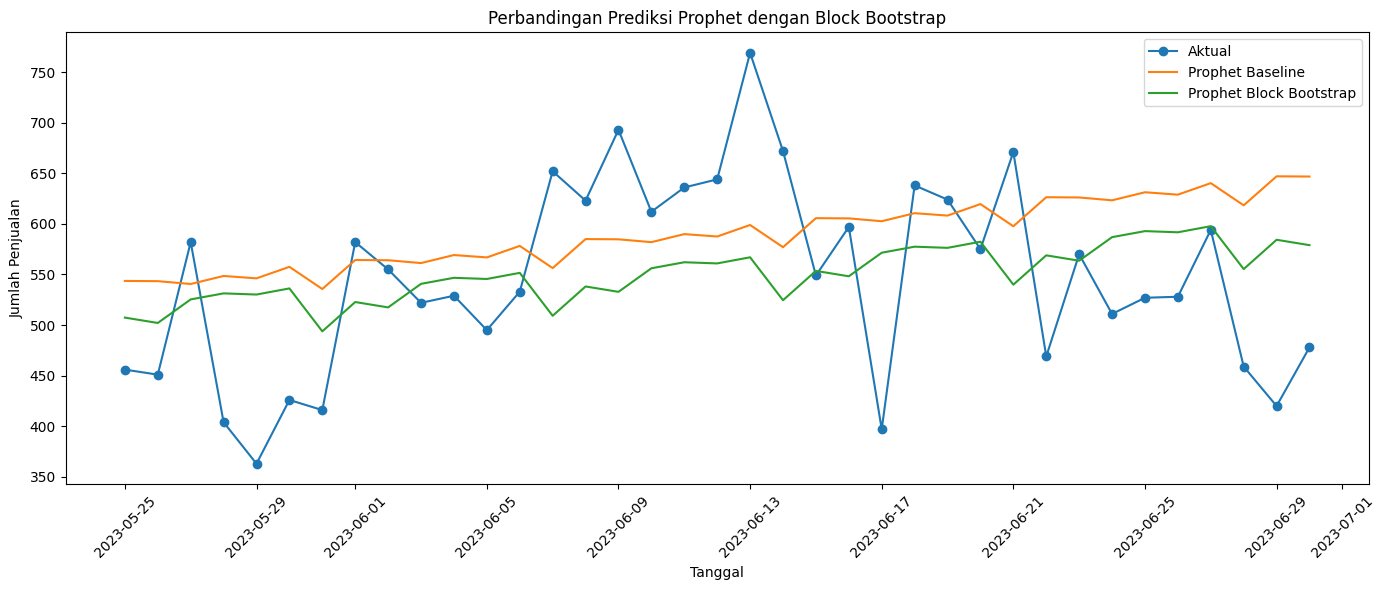

In [171]:
plt.figure(figsize=(14, 6))

plt.plot(
    test["ds"],
    test["y"],
    label="Aktual",
    marker="o"
)

plt.plot(
    test["ds"],
    prediksi_baseline,
    label="Prophet Baseline"
)

plt.plot(
    test["ds"],
    prediksi_bootstrap,
    label="Prophet Block Bootstrap"
)

plt.title(
    "Perbandingan Prediksi Prophet dengan Block Bootstrap"
)
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Karena kode sebelumnya membuat nilai sintetis berdasarkan prediksi in-sample Prophet ditambah residual bootstrap, hasil ini belum membuktikan bahwa Block Bootstrap secara umum meningkatkan akurasi. Perbaikannya mungkin dipengaruhi oleh satu realisasi residual sintetis dan perubahan pola yang dipelajari model.

1. Pastikan pembagian training dan testing sama untuk kedua model, termasuk tanggal testing.

2. Ulangi Block Bootstrap dengan beberapa random seed, misalnya 10, 21, 42, 100, dan 123. Periksa apakah perbaikannya konsisten, bukan hanya terjadi pada satu percobaan.

3. Jangan memilih parameter berdasarkan data testing. Gunakan data validasi untuk memilih panjang blok atau pengaturan augmentasi, lalu gunakan testing untuk evaluasi akhir

In [172]:
!pip install optuna quantile-forest

In [173]:
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from quantile_forest import RandomForestQuantileRegressor

# ==========================================
# 1. PERSIAPAN DATA RESIDUAL DARI TRAIN SET
# ==========================================
# Ambil prediksi Prophet pada data train untuk menghitung residual
train_forecast = model_baseline.predict(train)
train_fixed = train.copy()
train_fixed['yhat_prophet'] = train_forecast['yhat'].values

# Hitung Residual (Selisih data aktual - prediksi Prophet)
train_fixed['residual'] = train_fixed['y'] - train_fixed['yhat_prophet']

# Fungsi untuk membuat fitur tanggal sederhana
def create_time_features(df):
    df = df.copy()
    df['ds'] = pd.to_datetime(df['ds'])
    df['dayofweek'] = df['ds'].dt.dayofweek
    df['month'] = df['ds'].dt.month
    df['day'] = df['ds'].dt.day
    df['dayofyear'] = df['ds'].dt.dayofyear
    return df

train_feat = create_time_features(train_fixed)
X_train = train_feat[['dayofweek', 'month', 'day', 'dayofyear']]
y_train_residual = train_fixed['residual']


# ==========================================
# 2. OPTIMASI HIPERPARAMETER QRF DENGAN OPTUNA
# ==========================================
print("Sedang menjalankan Optuna untuk QRF...")

def objective(trial):
    # Definisikan rentang parameter yang akan dicari oleh Optuna
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step=25),
        'max_depth': trial.suggest_int('max_depth', 5, 25),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'random_state': 42
    }

    # Gunakan TimeSeriesSplit agar validasi silang sesuai dengan karakteristik data waktu
    tscv = TimeSeriesSplit(n_splits=3)
    maes = []

    for tr_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train_residual.iloc[tr_idx], y_train_residual.iloc[val_idx]

        # Inisialisasi dan latih QRF
        qrf = RandomForestQuantileRegressor(**params)
        qrf.fit(X_tr, y_tr)

        # Prediksi residual (mengambil kuantil 0.5 / median)
        preds = qrf.predict(X_val, quantiles=[0.5])
        if len(preds.shape) > 1:
            preds = preds.flatten()

        mae = mean_absolute_error(y_val, preds)
        maes.append(mae)

    return np.mean(maes)

# Jalankan studi Optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=15)

print("Hiperparameter QRF Terbaik ditemukan:", study.best_params)


# ==========================================
# 3. LATIH ULANG QRF MENGGUNAKAN PARAMETER TERBAIK
# ==========================================
best_qrf = RandomForestQuantileRegressor(**study.best_params)
best_qrf.fit(X_train, y_train_residual)


# ==========================================
# 4. PREDIKSI DAN EVALUASI PADA TEST SET
# ==========================================
# Siapkan data test
test_forecast = forecast_baseline.tail(len(test))
test_feat = create_time_features(test)
X_test = test_feat[['dayofweek', 'month', 'day', 'dayofyear']]

# Prediksi residual pada data test menggunakan QRF terbaik
pred_residual_test = best_qrf.predict(X_test, quantiles=[0.5])
if len(pred_residual_test.shape) > 1:
    pred_residual_test = pred_residual_test.flatten()

# Hasil Ensembel = Prediksi Prophet + Prediksi Residual QRF
y_pred_ensemble = test_forecast['yhat'].values + pred_residual_test

# Hitung Metrik Evaluasi Akhir
y_true = test['y'].values
mae_ens = mean_absolute_error(y_true, y_pred_ensemble)
rmse_ens = np.sqrt(mean_squared_error(y_true, y_pred_ensemble))

print(f"Ensembel (Prophet + QRF) -> MAE: {mae_ens:.2f} | RMSE: {rmse_ens:.2f}")

Sedang menjalankan Optuna untuk QRF...
Hiperparameter QRF Terbaik ditemukan: {'n_estimators': 150, 'max_depth': 21, 'min_samples_split': 2, 'min_samples_leaf': 1}
Ensembel (Prophet + QRF) -> MAE: 48.13 | RMSE: 55.88


In [174]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Definisi fungsi MAPE dan SMAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.maximum(1e-8, np.abs(y_true)))) * 100

def calculate_smape(y_true, y_pred):
    return 100 / len(y_true) * np.sum(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

# 2. Fungsi untuk menghasilkan semua metrik evaluasi
def evaluate_all_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': calculate_mape(y_true, y_pred),
        'SMAPE (%)': calculate_smape(y_true, y_pred),
        'R2-Score': r2_score(y_true, y_pred)
    }

# 3. Hitung metrik untuk Prophet Murni dan Ensemble menggunakan variabel yang benar
metrics_prophet = evaluate_all_metrics(y_true, prediksi_baseline)
metrics_ensemble = evaluate_all_metrics(y_true, y_pred_ensemble)

# 4. Buat tabel perbandingan yang rapi
comparison_table = pd.DataFrame(
    [metrics_prophet, metrics_ensemble],
    index=['Prophet Murni', 'Ensemble (Prophet + QRF)']
)

print("\n==================================================================")
print("             TABEL PERBANDINGAN EVALUASI MODEL FORECASTING        ")
print("==================================================================")
display(comparison_table.round(4))


             TABEL PERBANDINGAN EVALUASI MODEL FORECASTING        


,MAE,MSE,RMSE,MAPE (%),SMAPE (%),R2-Score
Prophet Murni,87.2320,10927.4044,104.5342,17.6828,15.9248,-0.2273
Ensemble (Prophet + QRF),48.1279,3122.6041,55.8803,9.2246,8.7437,0.6493


Reinforcement Learning

INFO:prophet:n_changepoints greater than number of observations. Using 24.


Training RL: 144 hari
Testing RL : 37 hari
Skala penyesuaian: 107.144

Jumlah observasi pengalaman RL: 112

Pelatihan Q-Learning Baru Selesai.
Ukuran Q-table yang benar: (63, 5)
Rata-rata reward 50 episode terakhir: 20.6823

PERBANDINGAN HASIL TESTING


,MAE,RMSE,WAPE (%),MAPE (%)
Model,,,,
Prophet,87.2320,104.5342,15.9608,17.6828
Prophet + QRF,48.1279,55.8803,8.8059,9.2246
Prophet + QRF + Q-Learning,55.4848,68.7996,10.1520,10.4407


,Tanggal,Aktual,Prediksi_Prophet,Prediksi_Ensemble,Aksi_RL,Koreksi_RL,Prediksi_Ensemble_RL
0,2023-05-25,456,543.630321,472.682118,-0.4,-42.857689,429.824429
1,2023-05-26,451,543.404265,472.456063,-0.4,-42.857689,429.598373
2,2023-05-27,582,540.595157,514.455724,-0.4,-42.857689,471.598035
3,2023-05-28,404,548.543645,428.711052,-0.4,-42.857689,385.853362
4,2023-05-29,363,546.179838,426.347244,0.2,21.428845,447.776089
5,2023-05-30,426,557.560110,437.727516,0.4,42.857689,480.585206
6,2023-05-31,416,535.625965,415.793371,-0.4,-42.857689,372.935682
7,2023-06-01,582,564.308083,614.393170,0.4,42.857689,657.250859
8,2023-06-02,555,564.082028,614.167114,0.4,42.857689,657.024804
9,2023-06-03,522,561.272920,611.358007,0.4,42.857689,654.215696


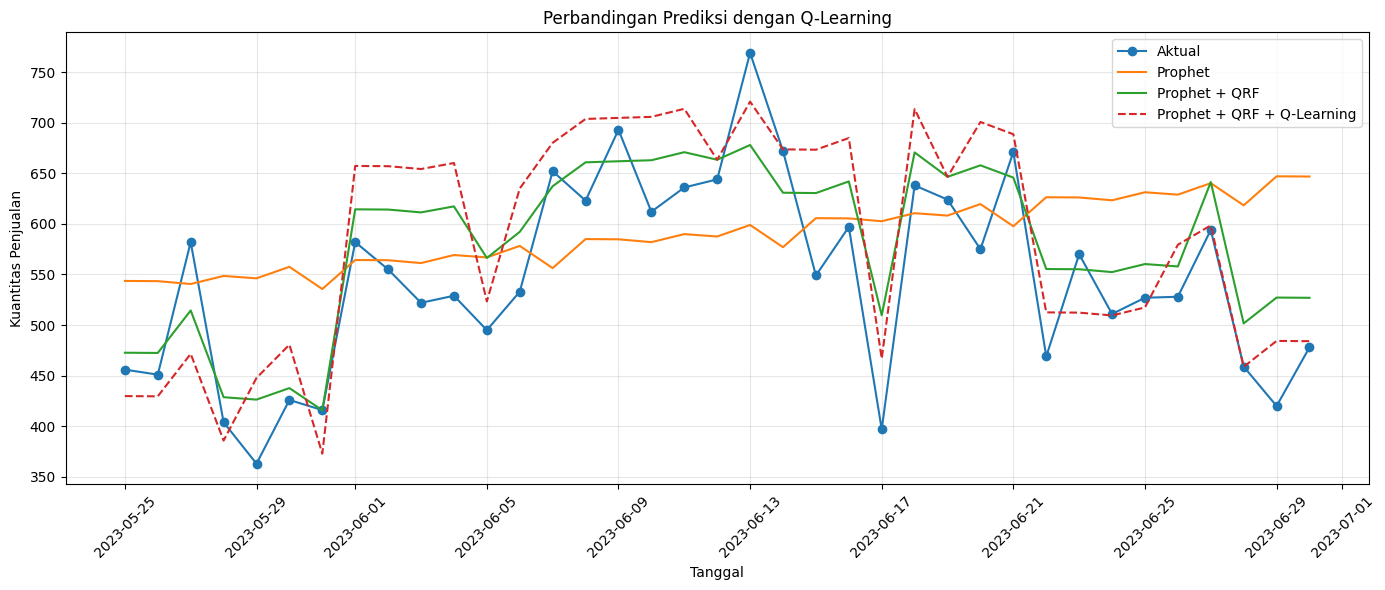

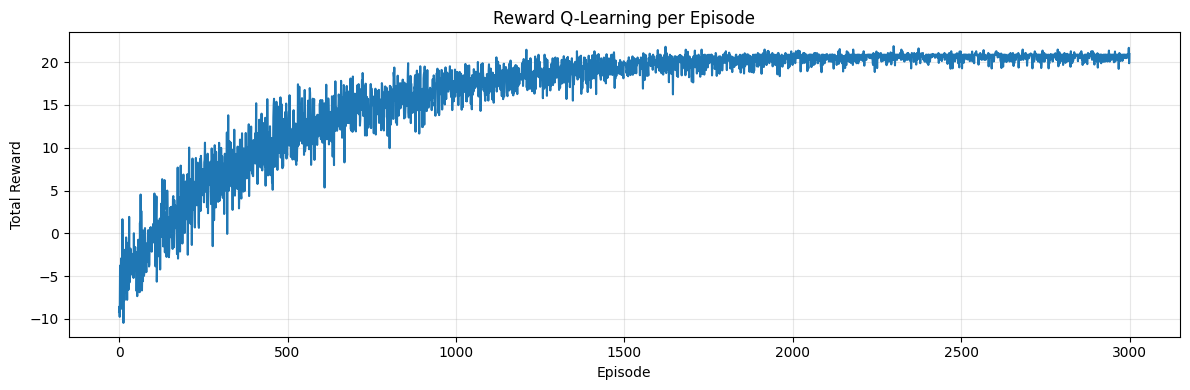

In [175]:
# ============================================================
# CELL 39: REINFORCEMENT LEARNING DENGAN Q-LEARNING (FIXED)
# Basis: hasil Prophet + QRF dari notebook sebelumnya
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prophet import Prophet
from quantile_forest import RandomForestQuantileRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. PERSIAPAN DATA DAN PARAMETER
# ------------------------------------------------------------

train_rl = train[["ds", "y"]].copy().reset_index(drop=True)
test_rl = test[["ds", "y"]].copy().reset_index(drop=True)

train_rl["ds"] = pd.to_datetime(train_rl["ds"])
test_rl["ds"] = pd.to_datetime(test_rl["ds"])

# Gunakan parameter QRF terbaik dari cell 37.
qrf_params_rl = study.best_params.copy()
qrf_params_rl["random_state"] = 42

def fitur_tanggal_rl(df):
    hasil = df[["ds"]].copy()
    hasil["ds"] = pd.to_datetime(hasil["ds"])
    hasil["dayofweek"] = hasil["ds"].dt.dayofweek
    hasil["month"] = hasil["ds"].dt.month
    hasil["day"] = hasil["ds"].dt.day
    hasil["dayofyear"] = hasil["ds"].dt.dayofyear
    return hasil[["dayofweek", "month", "day", "dayofyear"]]

X_train_rl = fitur_tanggal_rl(train_rl)
X_test_rl = fitur_tanggal_rl(test_rl)

# Skala penyesuaian aksi RL
SKALA_PENJUALAN = max(float(train_rl["y"].std()), 1.0)

print("Training RL:", len(train_rl), "hari")
print("Testing RL :", len(test_rl), "hari")
print("Skala penyesuaian:", round(SKALA_PENJUALAN, 3))

# ------------------------------------------------------------
# 2. MEMBUAT PREDIKSI WALK-FORWARD UNTUK PELATIHAN RL
# ------------------------------------------------------------
tscv_rl = TimeSeriesSplit(n_splits=4)
hasil_oof = []

for fold, (idx_tr, idx_val) in enumerate(tscv_rl.split(train_rl), start=1):
    data_tr = train_rl.iloc[idx_tr].copy()
    data_val = train_rl.iloc[idx_val].copy()

    # Prophet hanya dilatih pada bagian masa lalu
    prophet_fold = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode="additive",
        interval_width=0.95
    )
    prophet_fold.fit(data_tr)

    # Prediksi historis pada training untuk menghitung residual
    fc_tr = prophet_fold.predict(data_tr[["ds"]])
    residual_tr = data_tr["y"].to_numpy() - fc_tr["yhat"].to_numpy()

    # Latih QRF pada residual dari periode training fold
    qrf_fold = RandomForestQuantileRegressor(**qrf_params_rl)
    qrf_fold.fit(fitur_tanggal_rl(data_tr), residual_tr)

    # Prediksi fold validasi
    fc_val = prophet_fold.predict(data_val[["ds"]])
    pred_prophet_fold = fc_val["yhat"].to_numpy()

    pred_residual_fold = qrf_fold.predict(
        fitur_tanggal_rl(data_val),
        quantiles=[0.5]
    ).reshape(-1)

    pred_ensemble_fold = pred_prophet_fold + pred_residual_fold

    hasil_oof.append(
        pd.DataFrame({
            "ds": data_val["ds"].to_numpy(),
            "y": data_val["y"].to_numpy(),
            "pred_prophet": pred_prophet_fold,
            "pred_residual_qrf": pred_residual_fold,
            "pred_ensemble": pred_ensemble_fold,
            "fold": fold
        })
    )

oof_rl = pd.concat(hasil_oof, ignore_index=True).sort_values("ds").reset_index(drop=True)
print("\nJumlah observasi pengalaman RL:", len(oof_rl))

# ------------------------------------------------------------
# 3. DEFINISI STATE DAN ACTION
# ------------------------------------------------------------
AKSI_RL = np.array([-0.40, -0.20, 0.00, 0.20, 0.40])
N_ACTIONS = len(AKSI_RL)
N_STATES = 7 * 3 * 3

# Batas level prediksi ditentukan hanya dari pengalaman training RL
batas_level = np.quantile(oof_rl["pred_ensemble"], [1/3, 2/3])

def buat_state_rl(tanggal, pred_ensemble, koreksi_qrf):
    tanggal = pd.to_datetime(tanggal)
    # State level prediksi
    level = np.digitize(pred_ensemble, bins=batas_level)
    # State arah koreksi QRF
    ambang_koreksi = 0.05 * SKALA_PENJUALAN
    if koreksi_qrf < -ambang_koreksi:
        arah = 0
    elif koreksi_qrf > ambang_koreksi:
        arah = 2
    else:
        arah = 1
    hari = tanggal.dayofweek
    return int(hari * 9 + level * 3 + arah)

state_oof = np.array([
    buat_state_rl(row.ds, row.pred_ensemble, row.pred_residual_qrf)
    for row in oof_rl.itertuples()
])

state_test = np.array([
    buat_state_rl(row.ds, y_pred_ensemble[i], pred_residual_test[i])
    for i, row in enumerate(test_rl.itertuples())
])

# ------------------------------------------------------------
# 4. MELATIH Q-LEARNING (DENGAN RE-INISIALISASI UKURAN Q-TABLE YANG BENAR)
# ------------------------------------------------------------
rng_rl = np.random.default_rng(42)
Q_table = np.zeros((N_STATES, N_ACTIONS))  # Di-inisialisasi ulang dengan ukuran 63 x 5

ALPHA = 0.02          # Learning rate stabil
GAMMA = 0.00          # 1-step MDP
EPSILON_AWAL = 1.00
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.998
EPISODES = 3000

reward_per_episode = []

y_oof = oof_rl["y"].to_numpy(dtype=float)
pred_oof = oof_rl["pred_ensemble"].to_numpy(dtype=float)

for episode in range(EPISODES):
    epsilon = max(EPSILON_MIN, EPSILON_AWAL * (EPSILON_DECAY ** episode))
    total_reward = 0.0

    for t in range(len(oof_rl)):
        state = state_oof[t]

        # Epsilon-greedy
        if rng_rl.random() < epsilon:
            action_idx = rng_rl.integers(N_ACTIONS)
        else:
            action_idx = int(np.argmax(Q_table[state]))

        # Terapkan aksi koreksi
        pred_rl = max(0.0, pred_oof[t] + AKSI_RL[action_idx] * SKALA_PENJUALAN)

        # Differential Reward
        error_awal = abs(y_oof[t] - pred_oof[t])
        error_rl = abs(y_oof[t] - pred_rl)
        reward = (error_awal - error_rl) / SKALA_PENJUALAN

        # Q-table update
        old_value = Q_table[state, action_idx]
        Q_table[state, action_idx] = old_value + ALPHA * (reward - old_value)

        total_reward += reward

    reward_per_episode.append(total_reward)

print("\nPelatihan Q-Learning Baru Selesai.")
print("Ukuran Q-table yang benar:", Q_table.shape)
print("Rata-rata reward 50 episode terakhir:", round(np.mean(reward_per_episode[-50:]), 4))

# ------------------------------------------------------------
# 5. TERAPKAN KEBIJAKAN RL PADA DATA TESTING
# ------------------------------------------------------------
aksi_terpilih = np.argmax(Q_table[state_test], axis=1)
koreksi_rl = AKSI_RL[aksi_terpilih] * SKALA_PENJUALAN
prediksi_rl = np.maximum(0, np.asarray(y_pred_ensemble, dtype=float) + koreksi_rl)

# ------------------------------------------------------------
# 6. EVALUASI: PROPHET, ENSEMBLE, DAN ENSEMBLE + RL
# ------------------------------------------------------------
def metrik_rl(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.maximum(np.asarray(y_pred, dtype=float), 0)
    error = y_true - y_pred
    mask = y_true != 0
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "WAPE (%)": (np.sum(np.abs(error)) / np.sum(np.abs(y_true)) * 100 if np.sum(np.abs(y_true)) != 0 else np.nan),
        "MAPE (%)": (np.mean(np.abs(error[mask] / y_true[mask])) * 100 if mask.any() else np.nan)
    }

hasil_rl = pd.DataFrame([
    {"Model": "Prophet", **metrik_rl(test_rl["y"], prediksi_baseline)},
    {"Model": "Prophet + QRF", **metrik_rl(test_rl["y"], y_pred_ensemble)},
    {"Model": "Prophet + QRF + Q-Learning", **metrik_rl(test_rl["y"], prediksi_rl)}
]).set_index("Model")

print("\nPERBANDINGAN HASIL TESTING")
display(hasil_rl.round(4))

# ------------------------------------------------------------
# 7. TABEL PREDIKSI AKHIR
# ------------------------------------------------------------
hasil_prediksi_rl = pd.DataFrame({
    "Tanggal": test_rl["ds"],
    "Aktual": test_rl["y"],
    "Prediksi_Prophet": np.asarray(prediksi_baseline),
    "Prediksi_Ensemble": np.asarray(y_pred_ensemble),
    "Aksi_RL": AKSI_RL[aksi_terpilih],
    "Koreksi_RL": koreksi_rl,
    "Prediksi_Ensemble_RL": prediksi_rl
})
display(hasil_prediksi_rl.head(15))

# ------------------------------------------------------------
# 8. VISUALISASI HASIL
# ------------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(test_rl["ds"], test_rl["y"], label="Aktual", marker="o")
plt.plot(test_rl["ds"], prediksi_baseline, label="Prophet")
plt.plot(test_rl["ds"], y_pred_ensemble, label="Prophet + QRF")
plt.plot(test_rl["ds"], prediksi_rl, label="Prophet + QRF + Q-Learning", linestyle="--")
plt.title("Perbandingan Prediksi dengan Q-Learning")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(reward_per_episode)
plt.title("Reward Q-Learning per Episode")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


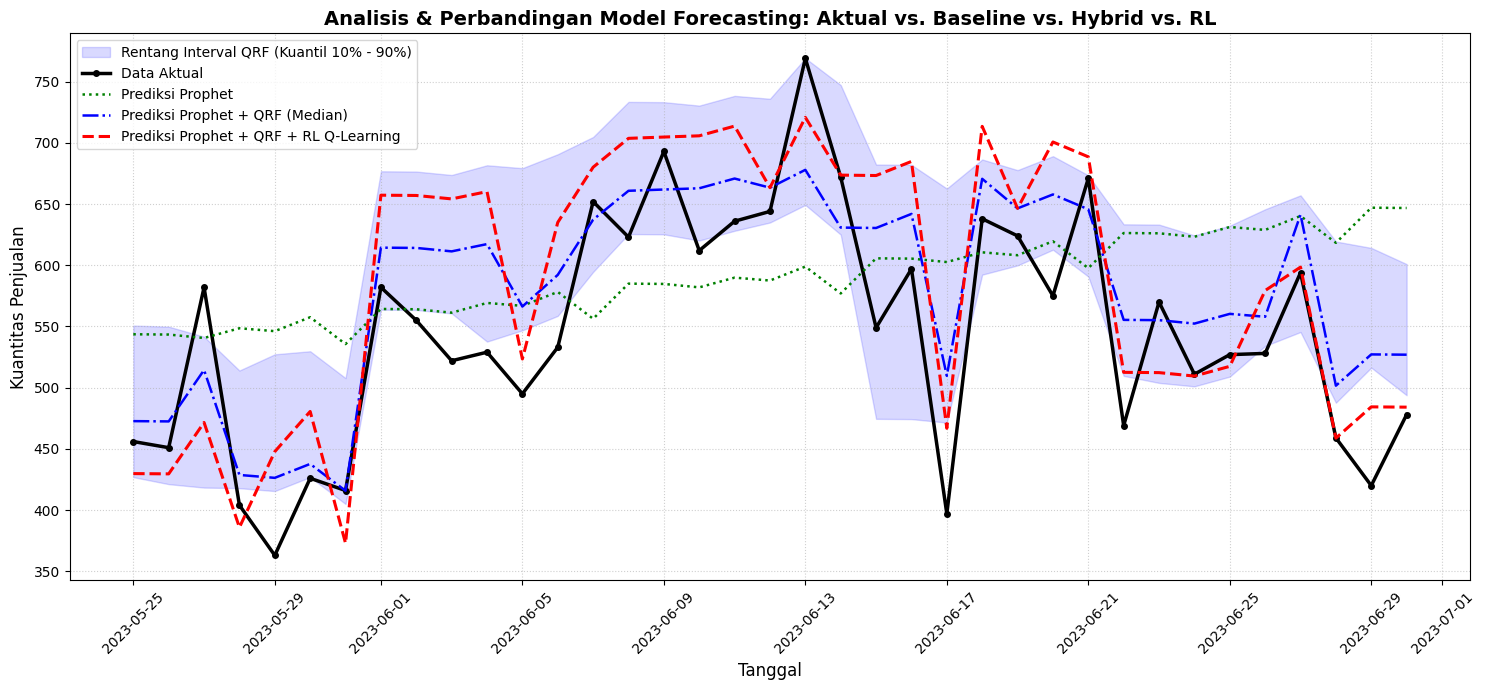

In [176]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Memastikan format tanggal sudah sesuai untuk plotting
tanggal_plot = pd.to_datetime(test_rl["ds"])

plt.figure(figsize=(15, 7))

# 1. Plot Area Arsiran Rentang Interval QRF (Kuantil 10% - 90%)
plt.fill_between(
    tanggal_plot,
    y_pred_lower,
    y_pred_upper,
    color="blue",
    alpha=0.15,
    label="Rentang Interval QRF (Kuantil 10% - 90%)"
)

# 2. Plot Data Aktual
plt.plot(
    tanggal_plot,
    test_rl["y"],
    label="Data Aktual",
    color="black",
    linewidth=2.5,
    marker="o",
    markersize=4
)

# 3. Plot Prediksi Prophet Murni
plt.plot(
    tanggal_plot,
    prediksi_baseline,
    label="Prediksi Prophet",
    color="green",
    linewidth=1.8,
    linestyle=":"
)

# 4. Plot Prediksi Prophet + QRF
plt.plot(
    tanggal_plot,
    y_pred_ensemble,
    label="Prediksi Prophet + QRF (Median)",
    color="blue",
    linewidth=1.8,
    linestyle="-."
)

# 5. Plot Prediksi Prophet + QRF + RL Q-Learning
plt.plot(
    tanggal_plot,
    prediksi_rl,
    label="Prediksi Prophet + QRF + RL Q-Learning",
    color="red",
    linewidth=2.2,
    linestyle="--"
)

# Pengaturan Layout dan Label Grafik
plt.title("Analisis & Perbandingan Model Forecasting: Aktual vs. Baseline vs. Hybrid vs. RL", fontsize=14, fontweight="bold")
plt.xlabel("Tanggal", fontsize=12)
plt.ylabel("Kuantitas Penjualan", fontsize=12)
plt.legend(fontsize=10, loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()